In [ ]:
import os
import re
from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
import json


# -------------------------------------------------------
# 1. Extract timestamps from filenames (chunking anchor)
# -------------------------------------------------------

FNAME_RE = re.compile(
    r".*-(\d{4})-(\d{2})-(\d{2})T(\d{2})-(\d{2})-(\d{2}\.\d+)Z"
)

def extract_datetime_from_filename(fname):
    m = FNAME_RE.match(fname)
    if not m:
        return None
    Y, M, D, h, m_, s = m.groups()
    return datetime(int(Y), int(M), int(D), int(h), int(m_), int(float(s)))


# -------------------------------------------------------
# 2. Group files by *day*
# -------------------------------------------------------

def group_files_by_day(sensor_dir):
    daily = {}

    for f in Path(sensor_dir).glob("SCD41.json-*"):
        dt = extract_datetime_from_filename(f.name)
        if dt is None:
            continue

        key = (dt.year, dt.month, dt.day)
        daily.setdefault(key, []).append(str(f))

    # sort each day’s file list
    for key in daily:
        daily[key] = sorted(daily[key])

    return daily


# -------------------------------------------------------
# 3. Load a single raw file
# -------------------------------------------------------

def load_data(file_path):
    rows = []

    with open(file_path, 'r', errors='ignore') as fh:
        for line in fh:
            raw = line.strip()
            if not raw or '\x00' in raw:
                continue

            try:
                entry = json.loads(raw)
            except json.JSONDecodeError:
                continue

            try:
                ts = datetime.strptime(entry['time'], "%m/%d/%Y %I:%M:%S %p")
            except Exception:
                continue

            rows.append({
                "timestamp": ts,
                "co2": entry.get("co2", np.nan),
                "temp": entry.get("temp", np.nan),
                "humidity": entry.get("humidity", np.nan),
            })

    if not rows:
        return None

    df = pd.DataFrame(rows).sort_values("timestamp")
    return df


# -------------------------------------------------------
# 4. Uptime calculation
# -------------------------------------------------------

def compute_uptime(df, mode="scd41", expected_hz=3.0, gap_factor=3.0):
    """
    Modes:
      - 'scd41'   → assumes 60s measurement cadence (or auto-detects ~60s)
      - 'activity'→ uptime = % of minutes with at least 1 sample
      - 'polling' → your original 3Hz uptime logic
      - 'auto'    → detect cadence by median(dt), then apply gap_factor rule
    """

    ts = df.index.to_series().sort_values()
    dt = ts.diff().dt.total_seconds().dropna()

    # -------------------------------------------------------
    # MODE: POLLING (original behavior)
    # -------------------------------------------------------
    if mode == "polling":
        expected_dt = 1.0 / expected_hz
        gap_threshold = gap_factor * expected_dt

        gaps = dt[dt > gap_threshold]
        total_time = (ts.iloc[-1] - ts.iloc[0]).total_seconds()
        downtime = gaps.sum()
        uptime = max(0.0, total_time - downtime)

        return {
            "start": ts.iloc[0],
            "end": ts.iloc[-1],
            "total_seconds": total_time,
            "downtime_seconds": float(downtime),
            "uptime_seconds": float(uptime),
            "uptime_ratio": float(uptime / total_time) if total_time > 0 else np.nan,
            "num_gaps": int(len(gaps)),
            "gap_threshold_seconds": float(gap_threshold),
            "mode": "polling"
        }

    # -------------------------------------------------------
    # MODE: AUTO — detect cadence
    # -------------------------------------------------------
    if mode == "auto":
        median_dt = float(np.median(dt[(dt > 0) & (dt < 600)]))  # ignore huge outliers
        expected_dt = median_dt
        gap_threshold = gap_factor * expected_dt

        gaps = dt[dt > gap_threshold]
        total_time = (ts.iloc[-1] - ts.iloc[0]).total_seconds()
        downtime = gaps.sum()
        uptime = max(0.0, total_time - downtime)

        return {
            "start": ts.iloc[0],
            "end": ts.iloc[-1],
            "total_seconds": total_time,
            "downtime_seconds": float(downtime),
            "uptime_seconds": float(uptime),
            "uptime_ratio": float(uptime / total_time) if total_time > 0 else np.nan,
            "num_gaps": int(len(gaps)),
            "gap_threshold_seconds": float(gap_threshold),
            "mode": f"auto (median_dt={median_dt:.2f}s)"
        }

    # -------------------------------------------------------
    # MODE: SCD41 (recommended)
    # Uses 60-second cadence, fallback to median(dt)
    # -------------------------------------------------------
    if mode == "scd41":
        # Detect if cadence looks like 1 sample/min
        median_dt = float(np.median(dt[(dt > 0) & (dt < 600)]))
        if 30 <= median_dt <= 90:
            expected_dt = median_dt  # auto-detected
        else:
            expected_dt = 60.0  # fallback

        gap_threshold = 2 * expected_dt  # allow missing 1 cycle

        gaps = dt[dt > gap_threshold]
        total_time = (ts.iloc[-1] - ts.iloc[0]).total_seconds()
        downtime = gaps.sum()
        uptime = max(0.0, total_time - downtime)

        return {
            "start": ts.iloc[0],
            "end": ts.iloc[-1],
            "total_seconds": total_time,
            "downtime_seconds": float(downtime),
            "uptime_seconds": float(uptime),
            "uptime_ratio": float(uptime / total_time) if total_time > 0 else np.nan,
            "num_gaps": int(len(gaps)),
            "gap_threshold_seconds": float(gap_threshold),
            "mode": f"scd41 (expected_dt={expected_dt:.2f}s)"
        }

    # -------------------------------------------------------
    # MODE: ACTIVITY (% of minutes with ≥1 sample)
    # -------------------------------------------------------
    if mode == "activity":
        df_min = df.resample("1min").count()
        minutes_total = len(df_min)
        minutes_valid = int((df_min["co2"] > 0).sum())

        uptime_ratio = minutes_valid / minutes_total if minutes_total > 0 else np.nan

        return {
            "start": ts.iloc[0],
            "end": ts.iloc[-1],
            "total_minutes": minutes_total,
            "minutes_with_samples": minutes_valid,
            "uptime_ratio": float(uptime_ratio),
            "mode": "activity"
        }

    raise ValueError(f"Unknown uptime mode: {mode}")



def log_uptime(out_uptime_csv, key, uptime_stats):
    df = pd.DataFrame([{
        "year": key[0],
        "month": key[1],
        "day": key[2],
        **uptime_stats
    }])

    write_header = not os.path.exists(out_uptime_csv)
    df.to_csv(out_uptime_csv, mode="a", header=write_header, index=False)

def remove_day_from_uptime_csv(uptime_csv, year, month, day):
    if not os.path.exists(uptime_csv):
        return

    df = pd.read_csv(uptime_csv)
    mask = ~(
        (df["year"] == year) &
        (df["month"] == month) &
        (df["day"] == day)
    )
    df = df[mask]
    df.to_csv(uptime_csv, index=False)


# -------------------------------------------------------
# 5. Process ONE DAY → 10-minute averages
# -------------------------------------------------------


def process_day(files, output_csv, uptime_csv, key, append=False, uptime_mode="scd41"):
    y, m, d = key
    dfs = []

    for f in files:
        df = load_data(f)
        if df is not None:
            dfs.append(df)

    if not dfs:
        print("No valid data for this day")
        return

    df_raw = pd.concat(dfs, ignore_index=True)
    df_raw = df_raw.sort_values("timestamp").set_index("timestamp")

    # Uptime
    uptime_stats = compute_uptime(df_raw, mode=uptime_mode)

    # Normalize timestamps
    start_ts = pd.to_datetime(uptime_stats["start"], errors="coerce")
    end_ts   = pd.to_datetime(uptime_stats["end"], errors="coerce")

    # If parsing failed, fall back to actual raw timestamps
    if pd.isna(start_ts):
        start_ts = df_raw.index.min()
    if pd.isna(end_ts):
        end_ts = df_raw.index.max()

    uptime_stats["start"] = start_ts
    uptime_stats["end"]   = end_ts

    uptime_stats["year"] = y
    uptime_stats["month"] = m
    uptime_stats["day"] = d

    log_uptime(uptime_csv, key, uptime_stats)

    # 10-minute average resampling
    df10 = df_raw.resample("10min").mean()
    df10["n_samples"] = df_raw["co2"].resample("10min").count()

    df10.to_csv(output_csv, mode="a" if append else "w",
                header=not append, index_label="timestamp")

    print(f"Written {len(df10)} rows.")

def remove_day_from_csv(csv_path, year, month, day):
    """Remove rows for a specific (year, month, day) from the dataset CSV."""
    if not os.path.exists(csv_path):
        return

    df = pd.read_csv(csv_path, parse_dates=["timestamp"])
    mask = ~(
        (df["timestamp"].dt.year == year) &
        (df["timestamp"].dt.month == month) &
        (df["timestamp"].dt.day == day)
    )
    df = df[mask]
    df.to_csv(csv_path, index=False)

def needs_sorting(df):
    """Return True if timestamps are not strictly non-decreasing."""
    ts = df["timestamp"]
    return (ts.diff().dropna() < pd.Timedelta(0)).any()

# -------------------------------------------------------
# 6. Orchestrate daily processing
# -------------------------------------------------------


def process_sensor_directory(sensor_dir, out_csv, uptime_csv,
                             year=None, month=None,
                             force=False, autosort=True, uptime_mode="scd41"):

    daily = group_files_by_day(sensor_dir)
    keys = sorted(daily.keys())

    # --- Filter by user selection ---
    if year is not None:
        keys = [k for k in keys if k[0] == year]
    if month is not None:
        keys = [k for k in keys if k[1] == month]

    print(f"Found {len(keys)} days to consider in {sensor_dir}")

    # --- Load uptime log (resume control) ---
    processed_days = set()
    if os.path.exists(uptime_csv) and not force:
        df_u = pd.read_csv(uptime_csv)
        processed_days = {(y, m, d) for y, m, d in zip(df_u.year, df_u.month, df_u.day)}

    # Will append unless file is empty or forcing first write
    first_write = not os.path.exists(out_csv)

    for key in keys:
        y, m, d = key

        # Skip if already processed unless force=True
        if not force and key in processed_days:
            print(f"Skipping already processed day: {key}")
            continue

        print(f"--- Processing day: {key} ---")

        # If reprocessing → delete old entries before recomputing
        if force:
            remove_day_from_csv(out_csv, y, m, d)
            remove_day_from_uptime_csv(uptime_csv, y, m, d)

            # If the CSV was emptied by this removal, next write must include header
            if os.path.exists(out_csv) and os.path.getsize(out_csv) == 0:
                first_write = True


        # Compute and append data chunk
        process_day(
            daily[key],
            output_csv=out_csv,
            uptime_csv=uptime_csv,
            key=key,
            append=not first_write,
            uptime_mode=uptime_mode
        )

        first_write = False

    print("DONE:", out_csv)
    print("Uptime log saved to:", uptime_csv)

    # --- AUTOSORT CSVs IF NEEDED ---
    if autosort and os.path.exists(out_csv):
        df = pd.read_csv(out_csv, parse_dates=["timestamp"])

        if needs_sorting(df):
            print("Detected out-of-order timestamps → sorting dataset CSV…")
            df = df.sort_values("timestamp")
            df.to_csv(out_csv, index=False)
            print("Sorted:", out_csv)
        else:
            print("Dataset CSV already sorted — no action needed.")

    if autosort and os.path.exists(uptime_csv):
        df_u = pd.read_csv(uptime_csv)

        # Check if uptime CSV is sorted by (year, month, day)
        order_cols = ["year", "month", "day"]

        if not df_u[order_cols].apply(tuple, axis=1).is_monotonic_increasing:
            print("Detected disordered uptime log → sorting…")
            df_u = df_u.sort_values(order_cols)
            df_u.to_csv(uptime_csv, index=False)
            print("Sorted:", uptime_csv)
        else:
            print("Uptime CSV already sorted — no action needed.")




In [66]:
sensor_dir = "/home/mbz/Documents/PhD/SCD41_DATA/IOT/CO2-SCT1-2M"
out_csv = "CO2_SCT1_2M_10min.csv"
uptime_csv = "CO2_SCT1_2M_uptime_log.csv"

process_sensor_directory(
    sensor_dir,
    out_csv,
    uptime_csv,
    year=2024,
    month=12,
    force=True
    )

Found 31 days to consider in /home/mbz/Documents/PhD/SCD41_DATA/IOT/CO2-SCT1-2M
--- Processing day: (2024, 12, 1) ---
Written 145 rows.
--- Processing day: (2024, 12, 2) ---
Written 145 rows.
--- Processing day: (2024, 12, 3) ---
Written 145 rows.
--- Processing day: (2024, 12, 4) ---
Written 145 rows.
--- Processing day: (2024, 12, 5) ---
Written 145 rows.
--- Processing day: (2024, 12, 6) ---
Written 145 rows.
--- Processing day: (2024, 12, 7) ---
Written 145 rows.
--- Processing day: (2024, 12, 8) ---
Written 145 rows.
--- Processing day: (2024, 12, 9) ---
Written 145 rows.
--- Processing day: (2024, 12, 10) ---
Written 145 rows.
--- Processing day: (2024, 12, 11) ---
Written 145 rows.
--- Processing day: (2024, 12, 12) ---
Written 145 rows.
--- Processing day: (2024, 12, 13) ---
Written 145 rows.
--- Processing day: (2024, 12, 14) ---
Written 145 rows.
--- Processing day: (2024, 12, 15) ---
Written 145 rows.
--- Processing day: (2024, 12, 16) ---
Written 145 rows.
--- Processing da

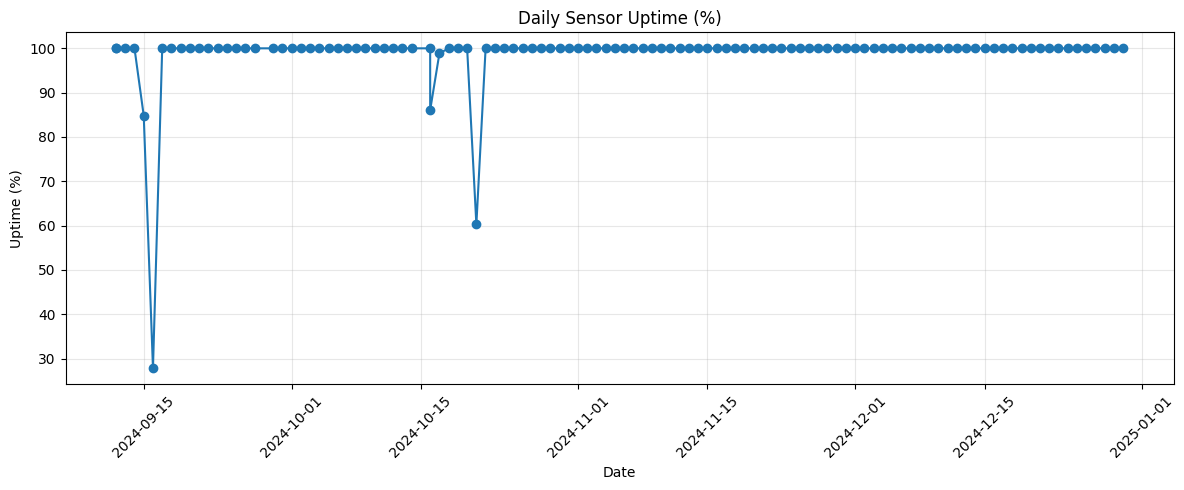

    year  month  day  uptime_ratio
4   2024      9   16      0.848148
5   2024      9   17      0.278282
35  2024     10   17      0.860575
40  2024     10   22      0.602657


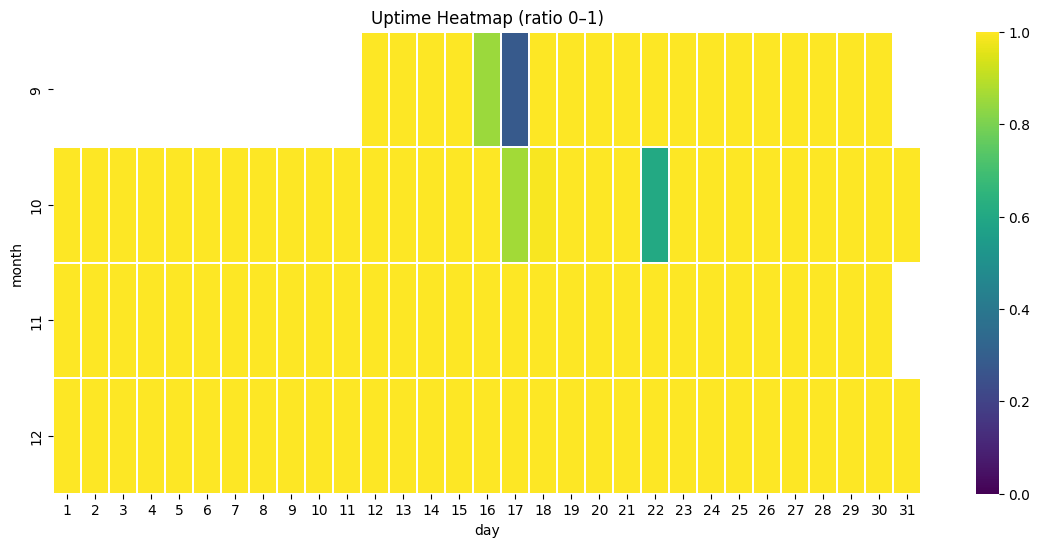

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(uptime_csv)

# -------------------------------------------------------
# Uptime time series plot
# -------------------------------------------------------

# Parse timestamp columns safely
df["start"] = pd.to_datetime(df["start"], errors="coerce")
df["end"]   = pd.to_datetime(df["end"], errors="coerce")

# Convert to DAY precision (pandas datetime, not Python date)
df["date"] = df["start"].dt.floor("D")

# Compute uptime %
df["uptime_pct"] = df["uptime_ratio"] * 100

# Drop rows missing date (e.g., malformed start timestamps)
df = df.dropna(subset=["date"])

plt.figure(figsize=(12,5))
plt.plot(df["date"], df["uptime_pct"], marker="o")
plt.ylabel("Uptime (%)")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.title("Daily Sensor Uptime (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Identify days with <95% uptime
dead = df[df["uptime_ratio"] < 0.95]
print(dead[["year", "month", "day", "uptime_ratio"]])


# -------------------------------------------------------
# Uptime heatmap
# -------------------------------------------------------
df = pd.read_csv("CO2_SCT1_2M_uptime_log.csv")

df["date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=df.day))

pivot = df.pivot(index="month", columns="day", values="uptime_ratio")

plt.figure(figsize=(14,6))
sns.heatmap(pivot, cmap="viridis", vmin=0, vmax=1, linewidths=0.1)
plt.title("Uptime Heatmap (ratio 0–1)")
plt.show()
